<a href="https://colab.research.google.com/github/Bousara/turbofan-predictive-maintenance/blob/main/notebooks/01_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
print("Bonjour, le projet commence !")

Bonjour, le projet commence !


In [5]:
import kagglehub

chemin = kagglehub.dataset_download("behrad3d/nasa-cmaps")
print("Données téléchargées ici :", chemin)

100%|██████████| 12.3M/12.3M [00:01<00:00, 8.45MB/s]

Extracting files...


Données téléchargées ici : /root/.cache/kagglehub/datasets/behrad3d/nasa-cmaps/versions/1


In [6]:
import os

for dossier, sous_dossiers, fichiers in os.walk(chemin):
    for f in fichiers:
        print(os.path.join(dossier, f))

/root/.cache/kagglehub/datasets/behrad3d/nasa-cmaps/versions/1/CMaps/train_FD002.txt
/root/.cache/kagglehub/datasets/behrad3d/nasa-cmaps/versions/1/CMaps/test_FD003.txt
/root/.cache/kagglehub/datasets/behrad3d/nasa-cmaps/versions/1/CMaps/RUL_FD004.txt
/root/.cache/kagglehub/datasets/behrad3d/nasa-cmaps/versions/1/CMaps/RUL_FD001.txt
/root/.cache/kagglehub/datasets/behrad3d/nasa-cmaps/versions/1/CMaps/Damage Propagation Modeling.pdf
/root/.cache/kagglehub/datasets/behrad3d/nasa-cmaps/versions/1/CMaps/test_FD002.txt
/root/.cache/kagglehub/datasets/behrad3d/nasa-cmaps/versions/1/CMaps/readme.txt
/root/.cache/kagglehub/datasets/behrad3d/nasa-cmaps/versions/1/CMaps/train_FD003.txt
/root/.cache/kagglehub/datasets/behrad3d/nasa-cmaps/versions/1/CMaps/train_FD004.txt
/root/.cache/kagglehub/datasets/behrad3d/nasa-cmaps/versions/1/CMaps/x.txt
/root/.cache/kagglehub/datasets/behrad3d/nasa-cmaps/versions/1/CMaps/test_FD004.txt
/root/.cache/kagglehub/datasets/behrad3d/nasa-cmaps/versions/1/CMaps/RU

In [7]:
import pandas as pd

dossier = os.path.join(chemin, "CMaps")

colonnes = ["moteur", "cycle", "reglage_1", "reglage_2", "reglage_3"] + \
           [f"capteur_{i}" for i in range(1, 22)]

train = pd.read_csv(os.path.join(dossier, "train_FD001.txt"),
                    sep=r"\s+", header=None, names=colonnes)

train.head()

,moteur,cycle,reglage_1,reglage_2,reglage_3,capteur_1,capteur_2,capteur_3,capteur_4,capteur_5,...,capteur_12,capteur_13,capteur_14,capteur_15,capteur_16,capteur_17,capteur_18,capteur_19,capteur_20,capteur_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [9]:
print(train.shape)
print("Nombre de moteurs :", train["moteur"].nunique())

(20631, 26)
Nombre de moteurs : 100


In [11]:
dernier_cycle = train.groupby("moteur")["cycle"].transform("max")
train["RUL"] = dernier_cycle - train["cycle"]

In [12]:
moteur_1 = train[train["moteur"] == 1]
print(moteur_1[["moteur", "cycle", "RUL"]].head())
print(moteur_1[["moteur", "cycle", "RUL"]].tail())

   moteur  cycle  RUL
0       1      1  191
1       1      2  190
2       1      3  189
3       1      4  188
4       1      5  187
     moteur  cycle  RUL
187       1    188    4
188       1    189    3
189       1    190    2
190       1    191    1
191       1    192    0


In [13]:
duree_vie = train.groupby("moteur")["cycle"].max()

print("Plus courte :", duree_vie.min(), "cycles")
print("Plus longue :", duree_vie.max(), "cycles")
print("Moyenne :", round(duree_vie.mean()), "cycles")

Plus courte : 128 cycles
Plus longue : 362 cycles
Moyenne : 206 cycles


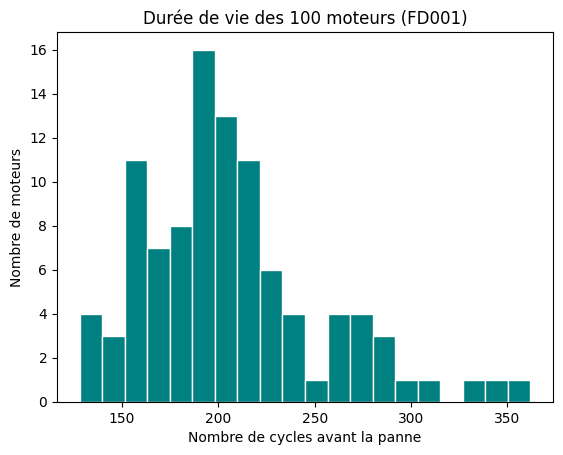

In [19]:
import matplotlib.pyplot as plt

plt.hist(duree_vie, bins=20, color="teal", edgecolor="white")
plt.xlabel("Nombre de cycles avant la panne")
plt.ylabel("Nombre de moteurs")
plt.title("Durée de vie des 100 moteurs (FD001)")
plt.show()